In [17]:
# /content/article1-screen1.png

In [18]:
!apt-get -qq install -y tesseract-ocr > /dev/null
!pip -q install -U transformers accelerate sentence-transformers pytesseract pandas pillow==10.4.0

In [19]:
import os, re, io, json, gc, time
from google.colab import drive

try:
    if not os.path.exists("/content/drive"):
        drive.mount("/content/drive")
    else:
        print("Google Drive ist bereits eingebunden.")
except Exception as e:
    print(f"Fehler beim Einbinden von Google Drive: {e}")
    print("Bitte stelle sicher, dass du das Berechtigungs-Popup in Colab bestätigt hast.")

# This must run before transformers / sentence_transformers are imported.

BASE      = "/content/drive/MyDrive/thesis/slidevqa_pilot"
IMG_DIR   = f"{BASE}/images"
CACHE_DIR = f"{BASE}/cache"
RES_DIR   = f"{BASE}/results"
for d in (IMG_DIR, CACHE_DIR, RES_DIR):
    try:
        os.makedirs(d, exist_ok=True)
    except Exception as e:
        print(f"Verzeichnis {d} konnte nicht erstellt werden (Drive nicht eingebunden?): {e}")

CSV_PATH      = "/content/sql-console-for-ntt-hil-insight-slidevqa.csv"   # <- path of YOUR csv
VLM_ID        = "Qwen/Qwen2.5-VL-3B-Instruct"
EMB_ID        = "BAAI/bge-m3"        # multilingual embedding model, same for all variants
OCR_LANG      = "eng"                # SlideVQA slides are English
POOL          = "global"             # "global": all slides of all decks; "deck": only the question's own deck
EVIDENCE_BASE = 1                    # assumed: evidence page numbers start at 1 (checked in cell 7)
KS            = (1, 3, 5)

Google Drive ist bereits eingebunden.


In [20]:
import pickle
import pandas as pd

ROWS_PATH = "/content/drive/MyDrive/thesis/slidevqa_10decks.pkl"   # new file, so the old 10-row pickle stays untouched
MAX_DECKS = 10      # number of different decks
PER_DECK  = 2       # questions per deck  -> 20 questions, ~200 slides
MAX_SCAN  = 300     # safety stop: never stream more than this many rows

if os.path.exists(ROWS_PATH):
    rows = pickle.load(open(ROWS_PATH, "rb"))
    print(len(rows), "rows loaded from Drive")
else:
    # SlideVQA is gated: accept the terms on its Hugging Face page first, then paste a token.
    from huggingface_hub import login
    login()
    from datasets import load_dataset, get_dataset_split_names

    splits = get_dataset_split_names("NTT-hil-insight/SlideVQA")
    print("splits:", splits)
    split = "test" if "test" in splits else splits[0]
    ds = load_dataset("NTT-hil-insight/SlideVQA", split=split, streaming=True)  # no 10 GB download

    per_deck, rows = {}, []
    for n, row in enumerate(ds, 1):
        deck_key = next((k for k in ("deck_name", "deck_url", "deck") if k in row), None)
        d = row[deck_key]
        if d not in per_deck and len(per_deck) >= MAX_DECKS:
            break                                   # rows are grouped by deck, so we have enough
        if per_deck.get(d, 0) < PER_DECK:
            rows.append(row)
            per_deck[d] = per_deck.get(d, 0) + 1
        if n >= MAX_SCAN:
            print("Stopped after", MAX_SCAN, "rows (safety limit)")
            break

    pickle.dump(rows, open(ROWS_PATH, "wb"))
    print(len(rows), "rows downloaded and saved to", ROWS_PATH)

print("decks:", len({str(r.get('deck_name', r.get('deck_url'))) for r in rows}))

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

Resolving data files:   0%|          | 0/53 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/53 [00:00<?, ?it/s]

splits: ['val', 'test', 'train']


Resolving data files:   0%|          | 0/53 [00:00<?, ?it/s]

Resolving data files:   0%|          | 0/53 [00:00<?, ?it/s]

19 rows downloaded and saved to /content/drive/MyDrive/thesis/slidevqa_10decks.pkl
decks: 10


In [21]:
r = rows[0]
for k, v in r.items():
    print(f"{k:25s} {type(v).__name__:15s} {str(v)[:90]}")

deck_name                 str             2012-02-20fy11roadshow-120221022442-phpapp02_95
deck_url                  str             https://www.slideshare.net/Nestle_IR/20120220-fy-11roadshow
page_1                    JpegImageFile   <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x576 at 0x7FD648114550>
page_2                    JpegImageFile   <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x576 at 0x7FD648115450>
page_3                    JpegImageFile   <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x576 at 0x7FD6481163F0>
page_4                    JpegImageFile   <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x576 at 0x7FD648114EB0>
page_5                    JpegImageFile   <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x576 at 0x7FD648114FF0>
page_6                    JpegImageFile   <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=1024x576 at 0x7FD648115130>
page_7                    JpegImageFile   <PIL.JpegImagePl

In [22]:
import ast, base64
from PIL import Image

def to_pil(v):
    """Turn whatever the CSV holds for an image into a PIL image (None if it is not an image)."""
    if isinstance(v, Image.Image):
        return v
    if isinstance(v, (bytes, bytearray)):
        return Image.open(io.BytesIO(v))
    if isinstance(v, dict):
        if v.get("bytes"):
            return Image.open(io.BytesIO(v["bytes"]))
        if v.get("path") and os.path.exists(v["path"]):
            return Image.open(v["path"])
        return None
    if isinstance(v, str):
        t = v.strip()
        if t.startswith("{") and "bytes" in t:            # pandas export of {'bytes': b'...', 'path': ...}
            try:
                return to_pil(ast.literal_eval(t))
            except Exception:
                return None
        if os.path.exists(t):                              # a file path
            return Image.open(t)
        if t.startswith("http"):                           # a URL (may have expired)
            import requests
            r = requests.get(t, timeout=30)
            return Image.open(io.BytesIO(r.content)) if r.ok else None
        if len(t) > 200 and " " not in t:                  # base64
            try:
                return Image.open(io.BytesIO(base64.b64decode(t)))
            except Exception:
                return None
    return None

def find_field(row, candidates):
    return next((c for c in candidates if c in row), None)

def slide_images(row):
    """Return the deck's slide images in page order (positions 1..N)."""
    cols = []
    for k, v in row.items():                      # one column per page, e.g. page_1 ... page_20
        m = re.fullmatch(r"(?:page|image|slide)_?(\d+)", k)
        if m and to_pil(v) is not None:
            cols.append((int(m.group(1)), to_pil(v)))
    if cols:
        return [img for _, img in sorted(cols, key=lambda x: x[0])]
    for k, v in row.items():                      # or one column holding a list of images
        if isinstance(v, (list, tuple)) and v and to_pil(v[0]) is not None:
            return [to_pil(x) for x in v]
    raise ValueError("No slide images found. Check the field printout and adapt slide_images().")

def parse_pages(ev):
    if isinstance(ev, str):
        return [int(x) for x in re.findall(r"\d+", ev)]
    if isinstance(ev, (int, float)):
        return [int(ev)]
    return [int(x) for x in ev]

In [23]:
r = rows[0]
Q_FIELD    = find_field(r, ["question"])
A_FIELD    = find_field(r, ["answer"])
EV_FIELD   = find_field(r, ["evidence_pages", "evidence_page", "evidence"])
DECK_FIELD = find_field(r, ["deck_name", "deck_url", "deck"])
QID_FIELD  = find_field(r, ["qa_id", "question_id", "id"])
print(dict(question=Q_FIELD, answer=A_FIELD, evidence=EV_FIELD, deck=DECK_FIELD, qid=QID_FIELD))
assert Q_FIELD and EV_FIELD, "Set the field names by hand, using the printout from cell 4."

slides, questions = {}, []
for i, row in enumerate(rows):
    deck = str(row[DECK_FIELD]) if DECK_FIELD else f"deck{i}"
    deck = re.sub(r"[^A-Za-z0-9_-]+", "_", deck).strip("_")[-60:]
    if not any(s["deck"] == deck for s in slides.values()):       # save each deck only once
        for pos, img in enumerate(slide_images(row), start=1):
            pid = f"{deck}_p{pos:02d}"
            path = f"{IMG_DIR}/{pid}.png"
            if not os.path.exists(path):
                img.convert("RGB").save(path)
            slides[pid] = {"page_id": pid, "deck": deck, "pos": pos, "path": path}
    gold = [f"{deck}_p{p - EVIDENCE_BASE + 1:02d}" for p in parse_pages(row[EV_FIELD])]
    missing = [g for g in gold if g not in slides]
    if missing:
        print("WARNING: gold page not among saved slides:", missing)
    questions.append({
        "qid": str(row[QID_FIELD]) if QID_FIELD else f"q{i}",
        "deck": deck,
        "question_en": row[Q_FIELD],
        "answer": row.get(A_FIELD) if A_FIELD else None,
        "gold_pages": gold,
    })

slides_df = pd.DataFrame(slides.values())
q_df = pd.DataFrame(questions)
q_df.to_csv(f"{RES_DIR}/questions.csv", index=False)
print(f"{len(slides_df)} slides from {slides_df.deck.nunique()} decks, {len(q_df)} questions")
q_df[["qid", "question_en", "answer", "gold_pages"]]

{'question': 'question', 'answer': 'answer', 'evidence': 'evidence_pages', 'deck': 'deck_name', 'qid': 'qa_id'}
200 slides from 10 decks, 19 questions


,qid,question_en,answer,gold_pages
0,0,How much is the Trading Operating Profit in 2011?,12.5 bn,[2012-02-20fy11roadshow-120221022442-phpapp02_...
1,1,How much is the Trading Operating Profit in th...,12.5 bn,[2012-02-20fy11roadshow-120221022442-phpapp02_...
2,10,How many kinds of BICC Key Skills are there?,3,[rbiandbigdatainthe21stcentury-clean-140922112...
3,11,How many kinds of Business Intelligence Compet...,3,[rbiandbigdatainthe21stcentury-clean-140922112...
4,17,What is the title of the presentation that ALC...,AT THE SPEED OF IDEAS,[alcatel-lucenteesoverview-120403090342-phpapp...
5,18,What is the title of the presentation that the...,AT THE SPEED OF IDEAS,[alcatel-lucenteesoverview-120403090342-phpapp...
6,24,Which Activity is undertaken by more smartphon...,Social networks,[9c942a848ca9497686d609bddd-poli-150601151510-...
7,25,Which country spend the most in Mobile display...,Turkey,[9c942a848ca9497686d609bddd-poli-150601151510-...
8,31,How many points are listed for TAM Notes?,4,[a-151012171903-lva1-app6891_95_p12]
9,32,What is the abbreviation for Sales Qualified L...,SQL,[a-151012171903-lva1-app6891_95_p17]



Q: How much is the Trading Operating Profit in 2011?
A: 12.5 bn
Gold: ['2012-02-20fy11roadshow-120221022442-phpapp02_95_p05']


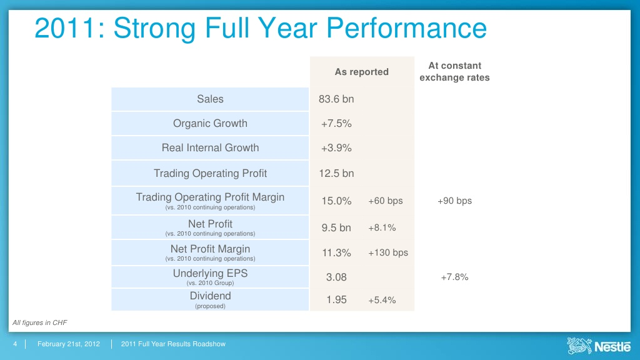


Q: How much is the Trading Operating Profit in the year Nestlé achieved the third largest Organic Growth in 10 years?
A: 12.5 bn
Gold: ['2012-02-20fy11roadshow-120221022442-phpapp02_95_p05', '2012-02-20fy11roadshow-120221022442-phpapp02_95_p07']


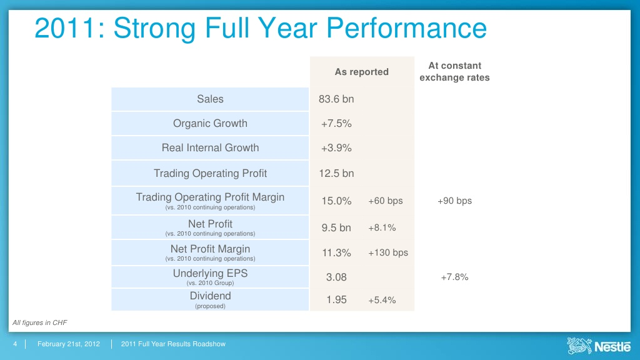

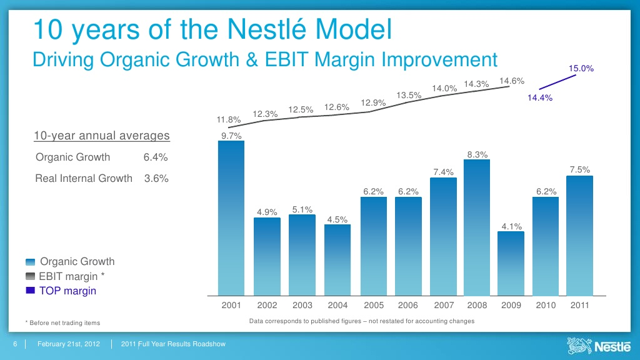

In [24]:
from IPython.display import display

for q in questions[:2]:
    print(f"\nQ: {q['question_en']}\nA: {q['answer']}\nGold: {q['gold_pages']}")
    for g in q["gold_pages"]:
        if g in slides:
            im = Image.open(slides[g]["path"])
            display(im.resize((640, int(640 * im.height / im.width))))

In [28]:
GERMAN = {
    "0": "Wie hoch ist das operative Handelsergebnis im Jahr 2011?",
    "1": "Wie hoch war das operative Ergebnis aus dem operativen Geschäft in dem Jahr, in dem Nestlé das dritthöchste organische Wachstum der letzten 10 Jahre erzielte?",
    "10": "Wie viele Arten von BICC-Schlüsselkompetenzen gibt es?",
    "11": "Wie viele Arten von Schlüsselkompetenzen für das Business Intelligence Competence Center gibt es?",
    "17": "Wie lautet der Titel der Präsentation, die ALCATEL-LUCENT für den ÜBERBLICK 2012 erstellt hat?",
    "18": "Wie lautet der Titel der Präsentation, die das Unternehmen, das 7 Nobelpreise gewonnen hatte, für den ÜBERBLICK 2012 erstellt hat?",
    "24": "Welche Aktivität wird von mehr Smartphone-Nutzern durchgeführt: E-Mail-Dienste oder soziale Netzwerke?",
    "25": "Welches Land gibt laut IAB Europe AdEx Benchmark (2013) im Jahr 2013 am meisten für mobile Display-Werbung aus?",
    "31": "Wie viele Punkte sind für TAM-Notizen aufgeführt?",
    "32": "Was ist die Abkürzung für Sales Qualified Leads?",
    "34": "Was ist das Hauptziel neben der Gewinnung von Aufmerksamkeit und dem Hinterlassen eines nützlichen, bleibenden Eindrucks?",
    "35": "Was wird in 'A framework of psychological meaning' als Beispiele für soziale Merkmale aufgeführt?",
    "36": "Welcher Begriff bezieht sich auf die Art und Weise, wie dem Team Arbeit zugewiesen wird?",
    "37": "In welchem Jahr ist der Prozentsatz der von Regierungen garantierten subnationalen Schulden höher, 2015 oder 2016?",
    "38": "In welchem Jahr werden subnationale Schulden möglicherweise stärker durch die Regierung entlastet, 2015 oder 2016?",
    "40": "Was passiert vor der Reizung des parietalen Peritoneums?",
    "41": "Welcher Teil des Blinddarms zeigt die Anzeichen/Symptome von Durchfall und krampfartigen Schmerzen?",
    "43": "Wie hoch ist der Prozentsatz der Befragten, die antworten, dass allgemeiner Widerstand gegen Veränderungen die BARRIERE für eine weitere AGILE EINFÜHRUNG ist?",
    "44": "Wer ist der Autor des Buches mit dem Titel 'Reinventing organizations'?"
}

print("Template to copy into GERMAN above:\n")
for q in questions:
    print(f'    "{q["qid"]}": "",   # {q["question_en"]}')

for q in questions:
    q["question_de"] = GERMAN.get(q["qid"]) or None
print("\nGerman questions filled in:", sum(q["question_de"] is not None for q in questions), "/", len(questions))

Template to copy into GERMAN above:

    "0": "",   # How much is the Trading Operating Profit in 2011?
    "1": "",   # How much is the Trading Operating Profit in the year Nestlé achieved the third largest Organic Growth in 10 years?
    "10": "",   # How many kinds of BICC Key Skills are there?
    "11": "",   # How many kinds of Business Intelligence Competence Center Key Skills are there?
    "17": "",   # What is the title of the presentation that ALCATEL-LUCENT made for the OVERVIEW of 2012?
    "18": "",   # What is the title of the presentation that the company which had won 7 Nobel Prizes made for the OVERVIEW of 2012?
    "24": "",   # Which Activity is undertaken by more smartphone users, Email services or Social networks?
    "25": "",   # Which country spend the most in Mobile display ads in 2013, according to IAB Europe AdEx Benchmark (2013)?
    "31": "",   # How many points are listed for TAM Notes?
    "32": "",   # What is the abbreviation for Sales Qualified Leads?


In [29]:
import pytesseract

OCR_CACHE = f"{CACHE_DIR}/ocr_{OCR_LANG}.json"
ocr = json.load(open(OCR_CACHE)) if os.path.exists(OCR_CACHE) else {}

t0, todo = time.time(), [p for p in slides if p not in ocr]
for n, pid in enumerate(todo, 1):
    ocr[pid] = pytesseract.image_to_string(Image.open(slides[pid]["path"]), lang=OCR_LANG).strip()
    if n % 20 == 0 or n == len(todo):
        json.dump(ocr, open(OCR_CACHE, "w"), ensure_ascii=False, indent=1)
print(f"OCR: {len(todo)} new slides in {time.time() - t0:.0f}s, {len(ocr)} cached")
print("\nExample:\n", ocr[next(iter(slides))][:400])

OCR: 0 new slides in 0s, 200 cached

Example:
 


In [30]:
import torch
from transformers import AutoProcessor, AutoModelForImageTextToText

PROMPT_NAME = "visuals_en"
PROMPT = (
    "This is a presentation slide. Describe the charts, diagrams, tables and pictures on it: "
    "the type of visual, labels, axis names, units, and the values you can read. "
    "Do not copy the running text of the slide word for word, and do not guess values that are not visible."
)

DESC_CACHE = f"{CACHE_DIR}/desc_{VLM_ID.split('/')[-1]}_{PROMPT_NAME}.json"
desc = json.load(open(DESC_CACHE)) if os.path.exists(DESC_CACHE) else {}
todo = [p for p in slides if p not in desc]
print(f"{len(todo)} slides to describe ({len(desc)} already cached)")

if todo:
    processor = AutoProcessor.from_pretrained(VLM_ID, min_pixels=256 * 28 * 28, max_pixels=1024 * 28 * 28)
    vlm = AutoModelForImageTextToText.from_pretrained(VLM_ID, torch_dtype=torch.float16, device_map="auto").eval()
    stats = []
    for n, pid in enumerate(todo, 1):
        msgs = [{"role": "user", "content": [
            {"type": "image", "image": Image.open(slides[pid]["path"]).convert("RGB")},
            {"type": "text", "text": PROMPT}]}]
        inputs = processor.apply_chat_template(msgs, add_generation_prompt=True, tokenize=True,
                                               return_dict=True, return_tensors="pt").to(vlm.device)
        t1 = time.time()
        with torch.no_grad():
            out = vlm.generate(**inputs, max_new_tokens=256, do_sample=False)
        new = out[:, inputs["input_ids"].shape[1]:]
        desc[pid] = processor.batch_decode(new, skip_special_tokens=True)[0].strip()
        stats.append({"page_id": pid, "seconds": time.time() - t1, "out_tokens": int(new.shape[1])})
        if n % 5 == 0 or n == len(todo):
            json.dump(desc, open(DESC_CACHE, "w"), ensure_ascii=False, indent=1)
            print(f"  {n}/{len(todo)}  avg {sum(s['seconds'] for s in stats) / len(stats):.1f}s per slide")
    pd.DataFrame(stats).to_csv(f"{RES_DIR}/vlm_stats_{PROMPT_NAME}.csv", index=False)
    del vlm, processor
    gc.collect(); torch.cuda.empty_cache()

print("\nExample:\n", desc[next(iter(slides))][:500])

180 slides to describe (20 already cached)


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 2 files:   0%|          | 0/2 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/824 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

/usr/local/lib/python3.13/dist-packages/transformers/models/qwen2_vl/image_processing_qwen2_vl.py:129: FutureWarning: Passing `min_pixels` and `max_pixels` to a processor call is deprecated and will be removed in v5.23. Pass in `size={'longest_edge': xxx, 'shortest_edge': xxx} to override the target size.`
  warnings.warn(


  5/180  avg 7.5s per slide
  10/180  avg 9.9s per slide
  15/180  avg 11.2s per slide
  20/180  avg 11.5s per slide
  25/180  avg 10.9s per slide
  30/180  avg 11.1s per slide
  35/180  avg 11.0s per slide
  40/180  avg 11.5s per slide
  45/180  avg 11.4s per slide
  50/180  avg 11.8s per slide
  55/180  avg 11.6s per slide
  60/180  avg 11.7s per slide
  65/180  avg 11.7s per slide
  70/180  avg 11.7s per slide
  75/180  avg 11.7s per slide
  80/180  avg 11.9s per slide
  85/180  avg 11.7s per slide
  90/180  avg 11.6s per slide
  95/180  avg 11.7s per slide
  100/180  avg 11.7s per slide
  105/180  avg 11.7s per slide
  110/180  avg 11.8s per slide
  115/180  avg 11.7s per slide
  120/180  avg 11.6s per slide
  125/180  avg 11.6s per slide
  130/180  avg 11.7s per slide
  135/180  avg 11.7s per slide
  140/180  avg 11.7s per slide
  145/180  avg 11.7s per slide
  150/180  avg 11.7s per slide
  155/180  avg 11.7s per slide
  160/180  avg 11.6s per slide
  165/180  avg 11.7s per slide

In [33]:
from sentence_transformers import SentenceTransformer
import numpy as np

DESC_PREFIX = "Description of the visuals: "
VARIANTS = {
    "A_ocr":      lambda pid: [ocr.get(pid, "")],                                              # text only
    "C_merged":   lambda pid: [ocr.get(pid, "") + "\n\n" + DESC_PREFIX + desc.get(pid, "")],  # one chunk per slide
    "C_separate": lambda pid: [ocr.get(pid, ""), DESC_PREFIX + desc.get(pid, "")],             # description as own chunk
    "desc_only":  lambda pid: [desc.get(pid, "")],                                             # diagnostic only
}

emb = SentenceTransformer(EMB_ID, device="cuda")
emb.max_seq_length = 512

index = {}
for name, make in VARIANTS.items():
    meta = [{"page_id": pid, "deck": slides[pid]["deck"], "text": t}
            for pid in slides for t in make(pid) if t.strip() and t.strip() != DESC_PREFIX.strip()]
    vecs = emb.encode([m["text"] for m in meta], batch_size=16, normalize_embeddings=True, show_progress_bar=False)
    index[name] = (np.asarray(vecs), meta)
    print(f"{name:11s} {len(meta):4d} chunks")

Loading weights:   0%|          | 0/391 [00:00<?, ?it/s]

A_ocr        194 chunks
C_merged     200 chunks
C_separate   394 chunks
desc_only    200 chunks


In [34]:
def rank_pages(q_vec, vecs, meta, decks=None):
    """Score chunks, keep the best chunk score per page, return page_ids best-first."""
    scores = vecs @ q_vec
    best = {}
    for s, m in zip(scores, meta):
        if decks is not None and m["deck"] not in decks:
            continue
        if s > best.get(m["page_id"], -1e9):
            best[m["page_id"]] = float(s)
    return [p for p, _ in sorted(best.items(), key=lambda x: -x[1])]

def score(ranking, gold, ks=(1, 3, 5)):
    """Hit@k: at least one gold page in the top k. MRR: 1 / rank of the first gold page."""
    first = next((i for i, p in enumerate(ranking, 1) if p in gold), None)
    out = {f"Hit@{k}": float(first is not None and first <= k) for k in ks}
    out["MRR"] = 1.0 / first if first else 0.0
    out["rank"] = first
    return out

In [35]:
records, top = [], {}
for q in questions:
    for lang in ("en", "de"):
        text = q.get(f"question_{lang}")
        if not text:
            continue
        q_vec = emb.encode(text, normalize_embeddings=True)
        decks = None if POOL == "global" else {q["deck"]}
        for name, (vecs, meta) in index.items():
            ranking = rank_pages(q_vec, vecs, meta, decks)
            top[(q["qid"], lang, name)] = ranking[:5]
            records.append({"qid": q["qid"], "lang": lang, "variant": name, **score(ranking, q["gold_pages"], KS)})

res = pd.DataFrame(records)
res.to_csv(f"{RES_DIR}/retrieval_{POOL}_{time.strftime('%Y%m%d_%H%M')}.csv", index=False)

summary = res.groupby(["lang", "variant"]).agg(
    n=("qid", "count"), **{f"Hit@{k}": (f"Hit@{k}", "mean") for k in KS}, MRR=("MRR", "mean")).round(2)
print(f"Pool: {POOL} ({len(slides)} slides). ~10 questions: one question = ~10 points, so a pipeline check only.\n")
display(summary)
display(res.pivot_table(index=["qid", "lang"], columns="variant", values="rank"))

Pool: global (200 slides). ~10 questions: one question = ~10 points, so a pipeline check only.



n  Hit@1  Hit@3  Hit@5   MRR
lang variant                                  
de   A_ocr       19   0.58   0.79   0.89  0.71
     C_merged    19   0.79   0.95   0.95  0.88
     C_separate  19   0.74   0.95   0.95  0.85
     desc_only   19   0.79   0.89   0.95  0.85
en   A_ocr       19   0.68   0.84   0.89  0.77
     C_merged    19   0.95   1.00   1.00  0.97
     C_separate  19   0.89   1.00   1.00  0.95
     desc_only   19   0.89   0.95   1.00  0.93

variant   A_ocr  C_merged  C_separate  desc_only
qid lang                                        
0   de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
1   de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
10  de      4.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
11  de      2.0       1.0         2.0        1.0
    en      2.0       1.0         2.0        1.0
17  de      1.0       1.0         1.0        3.0
    en      1.0       1.0         1.0        4.0
18  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
24  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
25  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
31  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
32  de     32.0       1.0         1.0        1.0
    en     37.0       1.0         1.0        1.0
34  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
35  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
36  de      2.0       2.0         2.0        7.0
    en      1.0       1.0         1.0        1.0
37  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
38  de      1.0       1.0         1.0        1.0
    en      1.0       1.0         1.0        1.0
40  de     10.0       2.0         2.0        1.0
    en     10.0       1.0         1.0        1.0
41  de      5.0       7.0         7.0        4.0
    en      4.0       1.0         1.0        1.0
43  de      2.0       2.0         2.0        2.0
    en      2.0       2.0         2.0        2.0
44  de      3.0       1.0         1.0        1.0
    en      3.0       1.0         1.0        1.0